In [10]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [13]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isnull().sum()

np.int64(11)

In [15]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


In [16]:
df = df.dropna(subset=["TotalCharges"])
df.shape

(7032, 21)

In [17]:
df.duplicated(subset="customerID").sum()

np.int64(0)

In [18]:
df["Churn_num"] = df["Churn"].map({"No": 0, "Yes": 1})
df[["Churn", "Churn_num"]].head()

,Churn,Churn_num
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [19]:
df.to_csv("telco_churn_clean.csv", index=False)

In [21]:
import sqlite3
conn = sqlite3.connect(":memory:")
df.to_sql("customers", conn, index=False, if_exists="replace")

def q(sql):
    return pd.read_sql(sql, conn)

In [22]:
q("""
SELECT Contract,
       COUNT(*) AS customers,
       ROUND(AVG(Churn_num) * 100, 1) AS churn_pct
FROM customers
GROUP BY Contract
ORDER BY churn_pct DESC
""")

,Contract,customers,churn_pct
0,Month-to-month,3875,42.7
1,One year,1472,11.3
2,Two year,1685,2.8


In [23]:
q("""
SELECT InternetService,
       COUNT(*) AS customers,
       ROUND(AVG(Churn_num) * 100, 1) AS churn_pct
FROM customers
GROUP BY InternetService
ORDER BY churn_pct DESC
""")

,InternetService,customers,churn_pct
0,Fiber optic,3096,41.9
1,DSL,2416,19.0
2,No,1520,7.4


In [24]:
q("""
SELECT PaymentMethod,
       COUNT(*) AS customers,
       ROUND(AVG(Churn_num) * 100, 1) AS churn_pct
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_pct DESC
""")

,PaymentMethod,customers,churn_pct
0,Electronic check,2365,45.3
1,Mailed check,1604,19.2
2,Bank transfer (automatic),1542,16.7
3,Credit card (automatic),1521,15.3


In [25]:
q("""
SELECT CASE WHEN tenure <= 12 THEN '1. 0-12 months'
            WHEN tenure <= 24 THEN '2. 13-24 months'
            WHEN tenure <= 48 THEN '3. 25-48 months'
            ELSE '4. 49+ months' END AS tenure_group,
       COUNT(*) AS customers,
       ROUND(AVG(Churn_num) * 100, 1) AS churn_pct
FROM customers
GROUP BY tenure_group
ORDER BY tenure_group
""")

,tenure_group,customers,churn_pct
0,1. 0-12 months,2175,47.7
1,2. 13-24 months,1024,28.7
2,3. 25-48 months,1594,20.4
3,4. 49+ months,2239,9.5


In [26]:
q("""
SELECT Churn,
       ROUND(AVG(MonthlyCharges), 1) AS avg_monthly_charge,
       ROUND(AVG(tenure), 1) AS avg_tenure_months
FROM customers
GROUP BY Churn
""")

,Churn,avg_monthly_charge,avg_tenure_months
0,No,61.3,37.7
1,Yes,74.4,18.0


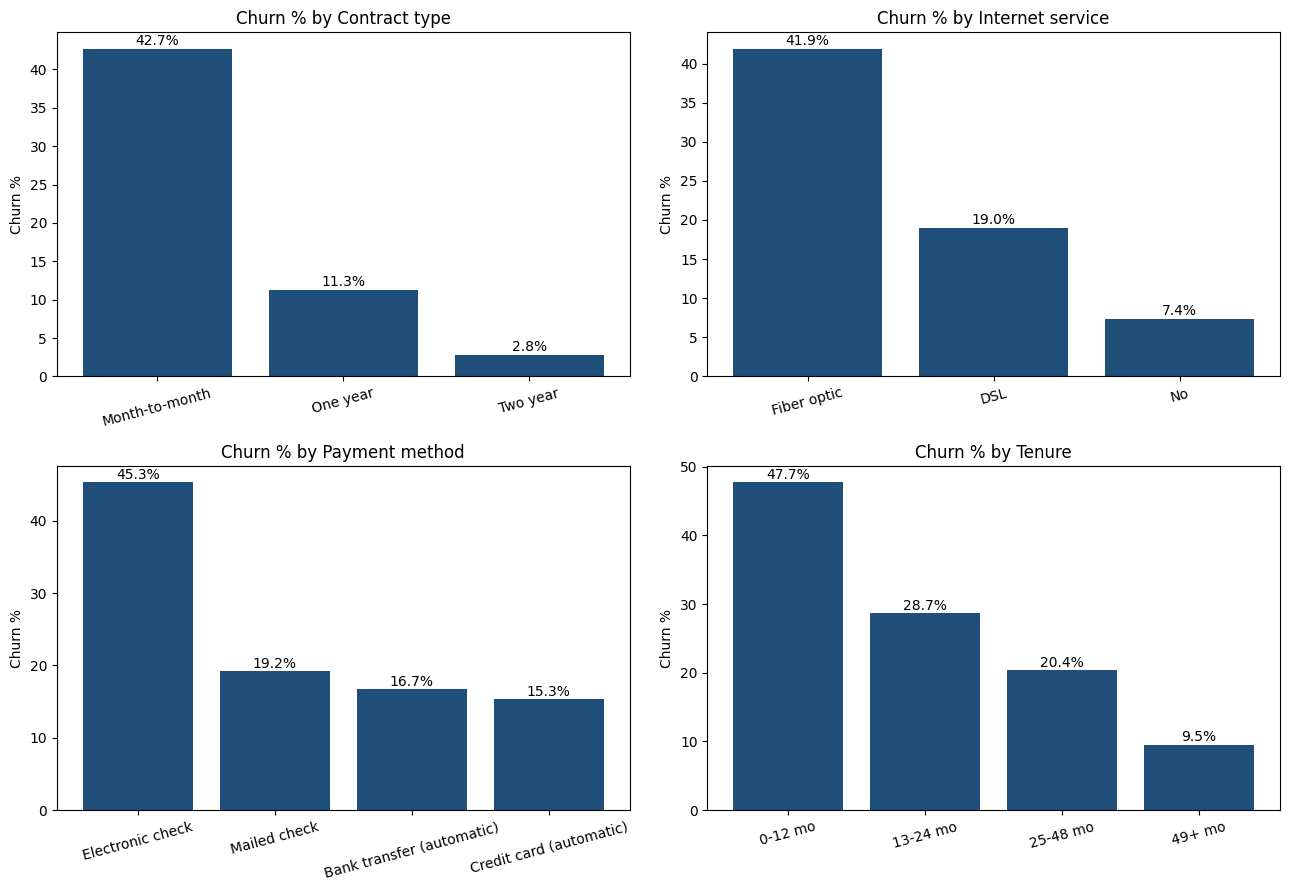

In [27]:
import matplotlib.pyplot as plt

df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 100],
                            labels=["0-12 mo", "13-24 mo", "25-48 mo", "49+ mo"])

cols = [("Contract", "Contract type"),
        ("InternetService", "Internet service"),
        ("PaymentMethod", "Payment method"),
        ("tenure_group", "Tenure")]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title) in zip(axes.flat, cols):
    d = (df.groupby(col, observed=True)["Churn_num"].mean() * 100).round(1).reset_index()
    if col != "tenure_group":
        d = d.sort_values("Churn_num", ascending=False)
    ax.bar(d[col].astype(str), d["Churn_num"], color="#1F4E78")
    ax.set_title("Churn % by " + title)
    ax.set_ylabel("Churn %")
    ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(d["Churn_num"]):
        ax.text(i, v + 0.5, f"{v}%", ha="center")

plt.tight_layout()
plt.savefig("churn_drivers.png", dpi=150)
plt.show()

In [28]:
model_df = df.drop(columns=["customerID", "Churn", "tenure_group"])

In [29]:
model_df = pd.get_dummies(model_df, drop_first=True, dtype=int)

X = model_df.drop(columns=["Churn_num"])   # the clues
y = model_df["Churn_num"]                  # the answer (0 or 1)
X.shape

(7032, 30)

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(5625, 30) (1407, 30)
0.266 0.266


In [31]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])
X_train_s[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5625.00,5625.00,5625.00
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.29,-1.55,-1.00
25%,-0.96,-0.97,-0.83
50%,-0.15,0.19,-0.39
75%,0.96,0.83,0.66
max,1.61,1.78,2.81


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

# tells XGBoost how much rarer churners are
spw = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"),
                            X_train_s, X_test_s),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                             class_weight="balanced", random_state=42),
                      X_train, X_test),
    "XGBoost": (XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                              scale_pos_weight=spw, eval_metric="logloss",
                              random_state=42),
                X_train, X_test),
}

rows, fitted = [], {}
for name, (m, Xtr, Xte) in models.items():
    m.fit(Xtr, y_train)
    pred = m.predict(Xte)
    prob = m.predict_proba(Xte)[:, 1]
    fitted[name] = m
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob)})

results = pd.DataFrame(rows).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.726,0.490,0.794,0.606,0.835
1,Random Forest,0.768,0.546,0.746,0.631,0.836
2,XGBoost,0.728,0.493,0.797,0.609,0.837


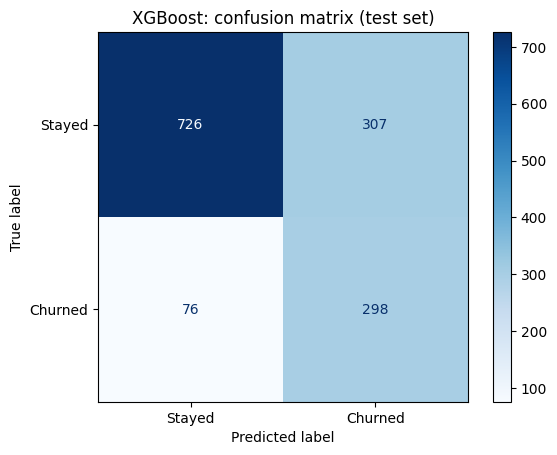

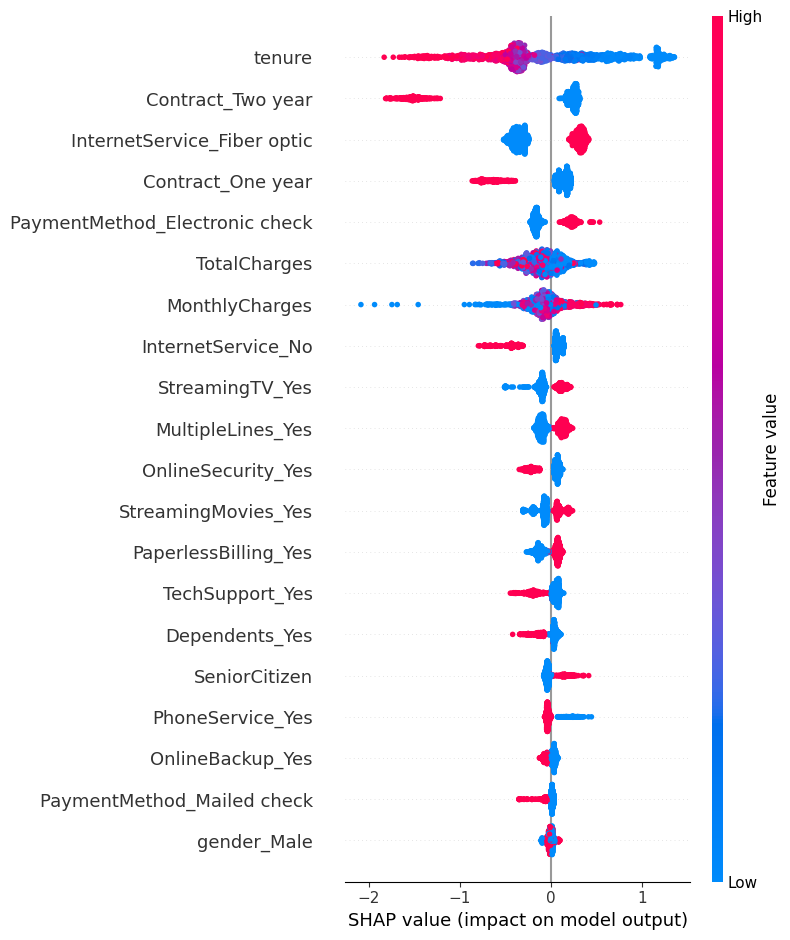

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import shap

best = fitted["XGBoost"]

# 1. Confusion matrix
pred = best.predict(X_test)
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("XGBoost: confusion matrix (test set)")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. SHAP: which factors drive churn
explainer = shap.TreeExplainer(best)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
churned = df[df["Churn_num"] == 1]
monthly_lost = churned["MonthlyCharges"].sum()
print("Customers churned:", len(churned))
print(f"Monthly revenue lost: ${monthly_lost:,.0f}")
print(f"Yearly revenue lost: ${monthly_lost*12:,.0f}")
print(f"Share of all monthly revenue: {monthly_lost / df['MonthlyCharges'].sum() * 100:.1f}%")

Customers churned: 1869
Monthly revenue lost: $139,131
Yearly revenue lost: $1,669,570
Share of all monthly revenue: 30.5%


In [35]:
pred = fitted["XGBoost"].predict(X_test)
test = X_test.copy()
test["actual"] = y_test.values
test["flagged"] = pred

success_rate = 0.30   # assumption: offer keeps 30% of churners
months_kept = 12      # assumption: a saved customer stays 12 more months

rows = []
for offer_cost in [10, 25, 50, 100]:
    flagged = test[test["flagged"] == 1]
    caught = flagged[flagged["actual"] == 1]
    gain_model = caught["MonthlyCharges"].sum() * success_rate * months_kept
    net_model = gain_model - len(flagged) * offer_cost

    all_churners = test[test["actual"] == 1]
    gain_all = all_churners["MonthlyCharges"].sum() * success_rate * months_kept
    net_all = gain_all - len(test) * offer_cost

    rows.append({"Offer cost ($)": offer_cost,
                 "Net: target flagged only": round(net_model),
                 "Net: offer to everyone": round(net_all)})

pd.DataFrame(rows)

,Offer cost ($),Net: target flagged only,Net: offer to everyone
0,10,74349,84875
1,25,65274,63770
2,50,50149,28595
3,100,19899,-41755


In [36]:
out = df.copy()
out["risk_score"] = fitted["XGBoost"].predict_proba(X)[:, 1].round(3)
out["risk_band"] = pd.cut(out["risk_score"], bins=[-0.01, 0.4, 0.7, 1.0],
                          labels=["Low", "Medium", "High"])
out.to_csv("churn_dashboard_data.csv", index=False)
out["risk_band"].value_counts()

,count
risk_band,
Low,3671
Medium,1687
High,1674
